# 15 Bright-emission checks: lost data, pile-up and a second instrument

Notebook 12 reproduces Dichiara's Table 2, but that only shows I did the same analysis of the same data, not that
the numbers are right. GRB 230307A is the second brightest GRB ever seen and GBM struggled with it. This notebook
asks how much that matters for E_peak, which is the number the project needs.

It also corrects something. Scripts 06 and 07 and the first version of notebook 12 said there was no sign of pile-up.
That was too strong: script 07's test leaves out b1, the detector with the highest rate, and the GBM team do report
pile-up in this burst.

1. What the GBM team report, and which of my windows it touches
2. Why 3-7 s: the summed rate against the telemetry limit
3. The rate in each detector against the pile-up threshold
4. Simulating the electronics, checked against the published calculation
5. How much pile-up should move E_peak, window by window
6. GBM against GECAM, an instrument that didn't saturate, in the same time bins
7. What the GBM/GECAM offset follows
8. b1's normalisation and the detectors compared in one energy band
9. The low-energy band
10. The precursor
11. Other detector choices: b0, and the NaI and b1 fitted apart
12. What goes in the error budget

Sections 4, 5 and part of 7 use simulated spectra. They are checks of how big an effect should be, and they are
labelled as such. Everything else is real data.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from gdt.core.pha import Pha
from gdt.core.data_primitives import EnergyBins
from gdt.core.background.primitives import BackgroundSpectrum
from gdt.core.spectra.functions import Band, Comptonized
from gdt.missions.fermi.gbm.phaii import GbmPhaii
from gdt.missions.fermi.gbm.tte import GbmTte

import settings_211211A
from settings import (DATA_DIR, BURST_ID, CODE_DIR, FIGURE_DIR, BKG_WINDOWS, BKG_ORDER, PRECURSOR, BAD_TIME_INTERVAL,
                      GBM_PILEUP, SPECTRAL_DETECTORS, FIT_RANGE_NAI, FIT_RANGE_BGO, WINDOWS_FILE, load_windows)
from spectral_fit_tools import (make_spectra, window_response, channel_mask, fit_model, scaled_starts, cstat, covariance,
                                energy_flux, load_spectra)
from lightcurve_tools import aligned_bin_edges, tte_path
from pileup_tools import record, channel_sampler

warnings.filterwarnings("ignore")     # GDT's fitter warns on most trial steps near the parameter limits
pd.set_option("display.width", 200)

SHARED = WINDOWS_FILE.parent
OUT_DIR = CODE_DIR / "spectra" / "time_resolved"
windows = load_windows()
epeak = pd.read_csv(SHARED / "epeak_230307A.csv").set_index("label")
ALL_DETECTORS = [f"n{i}" for i in range(10)] + ["na", "nb", "b0", "b1"]

## 1. What the GBM team report

The GBM team's statement on this burst is GCN Circular 33551 (Dalessi 2023), repeated on the Fermi caveats page:

> At particularly high rates the TTE data has data loss due to the bandwidth limit between the instrument and the
> spacecraft. [...] at particularly high rates both CTIME and CSPEC are affected by pulse pile-up, which will distort
> the spectra. [...] pulse pile-up occurs for GRB pulses during the time interval of 2.5-11.0 seconds for the BGO
> detector B1 and the interval 2.5-7.5 seconds for the NaI detector Na [...]. The TTE losses happen within these time
> intervals, with packet losses for high-rate GRB pulses between 3 to 7 seconds. We recommend the exclusion of these
> time intervals for GBM analysis of this burst, as well as caution in using bins adjacent to these selections.
> Additionally, due to the orientation of the burst, we recommend only using BGO detector B1 and NaI detector Na for
> analysis of this burst. All the other detectors either have >60deg source angles or are blocked by the spacecraft
> itself.

So there are two separate problems. Dichiara exclude 3-7 s, the TTE losses, but their windows run up to the edges and
use n6 and n8 as well. I follow Dichiara in notebook 12 in order to compare with their table, so these are the
shares of each of my windows that the GBM team would leave out:

In [2]:
def share(row, interval):
    overlap = max(0.0, min(row.t_stop, interval[1]) - max(row.t_start, interval[0]))
    return overlap / (row.t_stop - row.t_start)

flagged = pd.DataFrame({"t_start": windows.t_start, "t_stop": windows.t_stop,
                        "share_na_pileup": windows.apply(share, axis=1, interval=GBM_PILEUP["na"]),
                        "share_b1_pileup": windows.apply(share, axis=1, interval=GBM_PILEUP["b1"]),
                        "share_tte_losses": windows.apply(share, axis=1, interval=BAD_TIME_INTERVAL)})
flagged.round(2)

,t_start,t_stop,share_na_pileup,share_b1_pileup,share_tte_losses
label,,,,,
pre,-0.06,0.32,0.00,0.00,0.0
m01,0.32,3.00,0.19,0.19,0.0
m02,7.00,9.00,0.25,1.00,0.0
m03,9.00,11.00,0.00,1.00,0.0
m04,11.00,13.00,0.00,0.00,0.0
m05,13.00,15.00,0.00,0.00,0.0
m06,15.00,18.50,0.00,0.00,0.0
m07,18.50,22.00,0.00,0.00,0.0
m08,22.00,25.50,0.00,0.00,0.0


The precursor and everything after 11 s is clear. 0.32-3 s and 7-9 s have a quarter or less inside the na interval, but
b1 is flagged for all of 7-11 s, and 7-18 s, the window that goes with the 15 ms MVT, is about a third flagged in b1.

## 2. Why 3-7 s

Lesage et al. (2023, on GRB 221009A) give the reason for TTE losses: the summed rate of all detectors exceeds the 375 kHz
limit of GBM's high-speed science data bus and telemetry packets are lost. That can be tested directly: add up all 14
detectors, and look for gaps in the merged event stream. In a Poisson stream at a rate r, a gap dt has probability
exp(-r dt), so I use the same test as script 06, r dt > 20, which at 375 kcps finds gaps down to ~50 us.

In [3]:
TELEMETRY_LIMIT = 375.0      # kcps, summed over all detectors (Lesage et al. 2023; Meegan et al. 2009)

events = {}
for det in ALL_DETECTORS:
    tte = GbmTte.open(tte_path(DATA_DIR, BURST_ID, det))
    events[det] = np.sort(np.asarray(tte.data.times))
    tte.close()

edges = aligned_bin_edges((-2.0, 40.0), 0.016)
centres = 0.5 * (edges[:-1] + edges[1:])
rates = pd.DataFrame({det: np.histogram(events[det], bins=edges)[0] / np.diff(edges) / 1e3 for det in ALL_DETECTORS},
                     index=centres)                # kcps, all channels, as recorded
summed = rates.sum(axis=1)

merged = np.sort(np.concatenate([t[(t > edges[0]) & (t < edges[-1])] for t in events.values()]))
gap_lengths = np.diff(merged)
local_rate = np.interp(merged[:-1], centres, summed) * 1e3
is_gap = gap_lengths * local_rate > 20.0
gaps = pd.DataFrame({"t": merged[:-1][is_gap], "gap_ms": 1e3 * gap_lengths[is_gap],
                     "rate_kcps": local_rate[is_gap] / 1e3})

INTERVALS = {"precursor": PRECURSOR, "0.32-2.5 s": (0.32, 2.5), "2.5-3 s": (2.5, 3.0), "3-7 s": (3.0, 7.0),
             "7-7.5 s": (7.0, 7.5), "7.5-11 s": (7.5, 11.0), "11-15 s": (11.0, 15.0), "15-18.5 s": (15.0, 18.5),
             "18.5-40 s": (18.5, 40.0)}

def inside(index, interval):
    return (index > interval[0]) & (index < interval[1])

rows = []
for name, interval in INTERVALS.items():
    in_gaps = gaps[inside(gaps.t, interval)]
    rows.append({"interval": name, "summed_max_kcps": summed[inside(summed.index, interval)].max(),
                 "share_of_bins_above_350": (summed[inside(summed.index, interval)] > 350).mean(),
                 "gaps": len(in_gaps), "lost_ms": in_gaps.gap_ms.sum()})
pd.DataFrame(rows).set_index("interval").round(3)

,summed_max_kcps,share_of_bins_above_350,gaps,lost_ms
interval,,,,
precursor,119.313,0.000,1,1.362
0.32-2.5 s,361.125,0.015,1,1.068
2.5-3 s,196.875,0.000,0,0.000
3-7 s,377.687,0.149,9,6.050
7-7.5 s,252.937,0.000,0,0.000
7.5-11 s,339.937,0.000,0,0.000
11-15 s,227.000,0.000,1,1.252
15-18.5 s,151.812,0.000,0,0.000
18.5-40 s,106.500,0.000,0,0.000


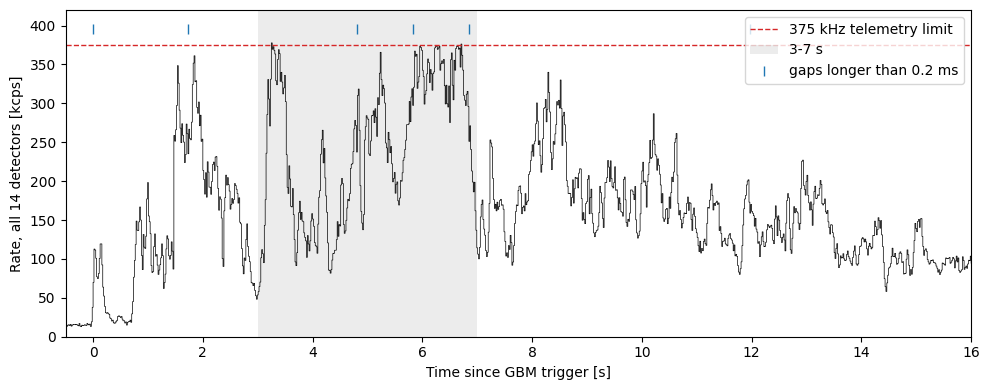

CSPEC bins start at [2.0000e-03 1.7280e+00 2.7520e+00 3.7760e+00 4.8000e+00 5.8240e+00
 6.8480e+00 7.8720e+00 8.8960e+00 9.9200e+00 1.0944e+01 1.1968e+01
 1.2992e+01]
gaps longer than 0.2 ms: 6
     t  gap_ms  rate_kcps  ms_after_cspec_edge
 0.004   1.362     61.095                1.580
 1.730   1.068    244.908                1.980
 4.801   1.972    252.272                0.974
 5.828   1.876    303.155                3.634
 6.850   1.346    267.303                2.146
11.970   1.252    164.325                1.690


In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(summed.index, summed, where="mid", color="k", lw=0.5)
ax.axhline(TELEMETRY_LIMIT, color="tab:red", ls="--", lw=1, label="375 kHz telemetry limit")
ax.axvspan(*BAD_TIME_INTERVAL, color="grey", alpha=0.15, lw=0, label="3-7 s")
long_gaps = gaps[gaps.gap_ms > 0.2].copy()
ax.plot(long_gaps.t, np.full(len(long_gaps), 395.0), "|", color="tab:blue", ms=7, label="gaps longer than 0.2 ms")
ax.set(xlim=(-0.5, 16), ylim=(0, 420), xlabel="Time since GBM trigger [s]", ylabel="Rate, all 14 detectors [kcps]")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "15_summed_rate.png", dpi=200)
plt.show()
cspec = GbmPhaii.open(sorted(DATA_DIR.glob(f"glg_cspec_b1_{BURST_ID}_v*.pha"))[-1])
cspec_starts = np.asarray(cspec.data.tstart)
cspec.close()
print("CSPEC bins start at", np.round(cspec_starts[(cspec_starts > -0.5) & (cspec_starts < 13.0)], 3))
long_gaps["ms_after_cspec_edge"] = [1e3 * (t - cspec_starts[cspec_starts <= t].max()) for t in long_gaps.t]
print(f"gaps longer than 0.2 ms: {len(long_gaps)}")
print(long_gaps.round(3).to_string(index=False))

The summed rate reaches the limit only inside 3-7 s. It peaks at 378 kcps there, and its tops look cut off flat at ~3.3 s
and between 5.9 and 6.7 s. Everywhere else it stays below: 361 kcps at ~1.8 s and 340 kcps at ~8.3 s. So 3-7 s isn't about
dead time, which is just as deep at ~1.8 s and ~8-10 s (script 06), or about pile-up: it's where GBM runs out of telemetry.
That answers the question script 06 left open.

A stream being limited should also look too regular. The number of events in short bins normally has variance/mean = 1,
a bit less here because dead time makes the stream slightly more even, so I measure that in 64 us bins inside each 16 ms bin,
after removing a straight line for the slow change in rate.

In [5]:
FANO_BIN = 64e-6       # s
variance_over_mean = []
for a, b in zip(edges[:-1], edges[1:]):
    counts = np.histogram(merged[(merged >= a) & (merged < b)], bins=np.arange(a, b + FANO_BIN / 2, FANO_BIN))[0]
    x = np.arange(len(counts))
    variance_over_mean.append(np.sum((counts - np.polyval(np.polyfit(x, counts, 1), x))**2) / (len(counts) - 2) / counts.mean())
variance_over_mean = pd.Series(variance_over_mean, index=centres)

rows = []
for a, b in ((50, 100), (100, 150), (150, 200), (200, 250), (250, 300), (300, 340), (340, 360), (360, 372), (372, 400)):
    in_group = (summed > a) & (summed <= b)
    rows.append({"summed_kcps": f"{a}-{b}", "bins": in_group.sum(), "bins_in_3_7s": (in_group & inside(summed.index, BAD_TIME_INTERVAL)).sum(),
                 "variance_over_mean": variance_over_mean[in_group].median()})
pd.DataFrame(rows).set_index("summed_kcps").round(3)

,bins,bins_in_3_7s,variance_over_mean
summed_kcps,,,
50-100,654,11,0.978
100-150,301,41,0.932
150-200,251,38,0.908
200-250,109,31,0.855
250-300,86,39,0.838
300-340,57,45,0.799
340-360,18,16,0.818
360-372,20,19,0.712
372-400,9,9,0.427


Variance/mean falls slowly with the rate, from 0.98 at 50-100 kcps to about 0.8 at 300-360 kcps, then drops to 0.71 at
360-372 kcps and 0.43 above 372 kcps. All but one of those 29 bins are inside 3-7 s. That is what clipping looks like.

The gaps I can find are small: 9 in 3-7 s, adding up to 6 ms of the 4 s. So either little is lost or most of it goes in pieces too
short for this test (under ~50 us); the TTE alone can't say which.

The six long gaps aren't random. Every one starts 1-4 ms after the edge of a CSPEC bin (table above), including the one at 0.004 s, just after
the bin that starts at the trigger. CSPEC bins last 1.024 s, so that many coincidences by chance would need about 4 ms in 1024 ms six times over.
Not every edge has a gap, and the one at 11.97 s happens at only 164 kcps, so these aren't the telemetry limit either. My guess is that the TTE
stream stalls briefly while the CSPEC spectra are written out, but I don't know the mechanism. They matter for any timing analysis: a gap looks
like a sudden drop in rate, and the one at 0.004 s is inside the precursor.

## 3. The rate in each detector

Pile-up happens separately in each detector. Lesage et al. put the onset at input rates above ~50 kcps. Chaplin et al.
(2013), who worked out GBM's pile-up from its pulse shape, say it becomes non-negligible at an input rate of ~100 kcps,
which is 60-70 kcps recorded.

In [6]:
def rate_table(rates, intervals, detectors):
    rows = []
    for name, interval in intervals.items():
        inner = rates[inside(rates.index, interval)]
        rows.append({"interval": name, **{det: f"{inner[det].median():.0f} / {inner[det].quantile(0.95):.0f} / {inner[det].max():.0f}"
                                          for det in detectors}})
    return pd.DataFrame(rows).set_index("interval")

print("Recorded rate, 16 ms bins, kcps: median / 95th percentile / maximum")
rate_table(rates, INTERVALS, ["n6", "n8", "na", "b0", "b1"])

Recorded rate, 16 ms bins, kcps: median / 95th percentile / maximum


,n6,n8,na,b0,b1
interval,,,,,
precursor,5 / 11 / 11,4 / 7 / 7,17 / 32 / 32,2 / 5 / 6,7 / 20 / 21
0.32-2.5 s,13 / 25 / 30,9 / 18 / 20,24 / 39 / 45,12 / 30 / 43,33 / 73 / 87
2.5-3 s,10 / 17 / 18,6 / 11 / 11,20 / 27 / 28,9 / 16 / 19,26 / 45 / 46
3-7 s,21 / 31 / 33,14 / 21 / 23,40 / 52 / 56,23 / 38 / 41,56 / 84 / 88
7-7.5 s,14 / 21 / 22,9 / 13 / 15,30 / 42 / 42,12 / 21 / 21,35 / 55 / 57
7.5-11 s,16 / 25 / 29,10 / 16 / 20,33 / 45 / 49,15 / 28 / 35,40 / 65 / 75
11-15 s,10 / 17 / 21,7 / 11 / 13,26 / 37 / 44,9 / 14 / 19,26 / 40 / 46
15-18.5 s,6 / 10 / 13,4 / 7 / 9,17 / 25 / 34,5 / 8 / 11,13 / 21 / 30
18.5-40 s,3 / 7 / 10,2 / 5 / 7,9 / 19 / 26,2 / 5 / 9,5 / 14 / 21


In [7]:
print("GRB 211211A, same bins, kcps: maximum over the burst")
for det in settings_211211A.SPECTRAL_DETECTORS:
    tte = GbmTte.open(tte_path(settings_211211A.DATA_DIR, settings_211211A.BURST_ID, det))
    edges_211 = aligned_bin_edges((-2.0, 80.0), 0.016)
    rate_211 = np.histogram(np.asarray(tte.data.times), bins=edges_211)[0] / 0.016 / 1e3
    tte.close()
    print(f"{det}: max {rate_211.max():.0f} at {edges_211[rate_211.argmax()]:.2f} s, 99th percentile {np.percentile(rate_211, 99):.0f}")

GRB 211211A, same bins, kcps: maximum over the burst
n2: max 51 at 7.34 s, 99th percentile 33
na: max 40 at 7.34 s, 99th percentile 25


b0: max 42 at 7.34 s, 99th percentile 23


b1 is the busiest detector by far. It stays above the 60-70 kcps threshold for long stretches of 3-7 s and reaches 75 kcps in
7.5-11 s, which fits its interval being longer than na's. na peaks at 56 kcps in 3-7 s and n6 and n8 never pass 33 kcps. After 11
s b1 stays below 46 kcps. One thing the rates don't explain: b1 also reaches 87 kcps at ~1.8 s, as high as anywhere in the
burst, yet the GBM team's interval only starts at 2.5 s. By rate alone that stretch would be flagged too, so in the next
sections I go by the rates and not by the interval.

The precursor is safe: b1 reaches 21 kcps and na 32 kcps. So is most of GRB 211211A: 51 kcps in n2 and 42 kcps in b0 at its very
peak, but the 99th percentiles are 33 and 23 kcps.

## 4. Simulating the electronics (a check)

Pile-up can't be undone from the counts alone, but it can be worked out from the pulse shape. `pileup_tools.py`
simulates what the electronics do, following Chaplin et al.: every detected photon adds a bipolar pulse to the voltage,
with a positive peak at 0.36 us and a negative lobe of 70% of the peak at ~1.6 us. The voltage is sampled every
0.104 us, an event is recorded at a maximum once the voltage has fallen for 4 samples, and the detector is then dead until
2.6 us have passed (10 us after an overflow event). Two photons within ~0.8 us add up (peak pile-up, which raises the
energy), and one landing on the negative lobe of another comes out low, or not at all (tail pile-up).

First I check the simulation against their Fig. 19, recorded rate against detection rate for four spectra, using values
read off the figure by eye.

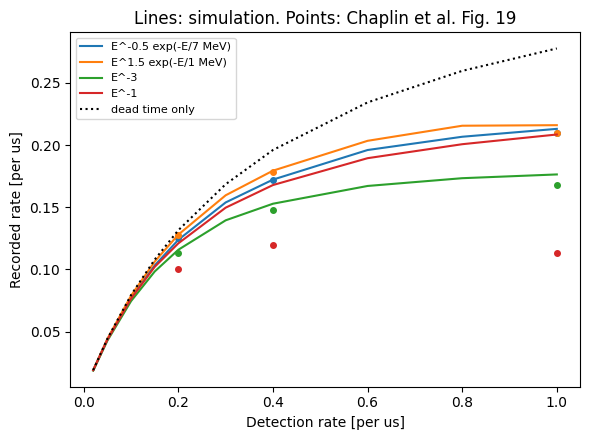

,"at 0.2/us: mine, theirs","at 0.4/us: mine, theirs","at 1.0/us: mine, theirs"
spectrum,,,
E^-0.5 exp(-E/7 MeV),"0.124, 0.125","0.172, 0.172","0.213, 0.210"
E^1.5 exp(-E/1 MeV),"0.128, 0.128","0.179, 0.178","0.216, 0.210"
E^-3,"0.116, 0.113","0.153, 0.148","0.176, 0.168"
E^-1,"0.121, 0.100","0.168, 0.120","0.209, 0.113"


In [8]:
rng = np.random.default_rng(15)
grid = np.logspace(np.log10(150.0), np.log10(40000.0), 4000)      # BGO-like range, as in their figure

def power_law_draw(index, cutoff=None):
    weight = grid**(index + 1)                 # per logarithmic step
    if cutoff:
        weight = weight * np.exp(-grid / cutoff)
    weight = weight / weight.sum()
    return lambda n: rng.choice(grid, n, p=weight)

SPECTRA = {"E^-0.5 exp(-E/7 MeV)": (power_law_draw(-0.5, 7000.0), {0.2: 0.125, 0.4: 0.172, 1.0: 0.21}),
           "E^1.5 exp(-E/1 MeV)": (power_law_draw(1.5, 1000.0), {0.2: 0.128, 0.4: 0.178, 1.0: 0.21}),
           "E^-3": (power_law_draw(-3.0), {0.2: 0.113, 0.4: 0.148, 1.0: 0.168}),
           "E^-1": (power_law_draw(-1.0), {0.2: 0.100, 0.4: 0.120, 1.0: 0.113})}
detection_rates = np.array([0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0])      # per us

fig, ax = plt.subplots(figsize=(6, 4.5))
rows = []
for name, (draw, read_off) in SPECTRA.items():
    recorded = []
    for lam in detection_rates:
        heights, total = record(draw, lam, 150.0, 1e9, 100000, rng)
        recorded.append(len(heights) / total)
    line, = ax.plot(detection_rates, recorded, label=name)
    ax.plot(list(read_off), list(read_off.values()), "o", color=line.get_color(), ms=4)
    rows.append({"spectrum": name, **{f"at {lam}/us: mine, theirs": f"{np.interp(lam, detection_rates, recorded):.3f}, {val:.3f}"
                                      for lam, val in read_off.items()}})
ax.plot(detection_rates, detection_rates / (1 + 2.6 * detection_rates), "k:", label="dead time only")
ax.set(xlabel="Detection rate [per us]", ylabel="Recorded rate [per us]", title="Lines: simulation. Points: Chaplin et al. Fig. 19")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "15_simulation_check.png", dpi=200)
plt.show()
pd.DataFrame(rows).set_index("spectrum")

For the three spectra with a cut-off or a steep slope, which are the ones closest to a burst's count spectrum, my curves are
within 5% of theirs. For E^-1 they part company above ~0.2 per us: 0.121 against 0.100 at 0.2 per us, and 0.209 against 0.113
at 1 per us. I don't know why; for a spectrum this flat my simulation loses fewer counts on the tails than their calculation.
At this burst's rates (b1's highest detection rate is ~0.11 per us) the curves all sit together, so it doesn't matter here,
but it does mean the simulation is a check of size and not a replacement for their calculation.

Now the effect on the spectrum, with this burst's own shape. I take the Band shape of 7-9 s, fold it through each
detector's response to get its count spectrum, simulate it at a range of recorded rates and compare what comes out with what
went in, after the usual dead-time correction. Simulated, so a check.

In [9]:
TAU, TAU_OVERFLOW = 2.6, 10.0      # us

def channel_edges(rsp):
    return np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges())

def simulate_counts(rsp, background_rate, theta, recorded_rates, durations, num_detections, rng):
    '''Piled-up and clean counts of one detector, for a fixed spectral shape at a list of recorded rates.

    theta is the Band shape, recorded_rates in per us, durations in us, background_rate per channel per us.
    The detection rate comes from the recorded rate with the dead-time formula.
    '''
    lo, hi = channel_edges(rsp)
    folded = np.asarray(rsp.drm.fold_spectrum(Band().eval, theta))
    overflow_share = folded[-1] / folded.sum()
    tau = TAU * (1 - overflow_share) + TAU_OVERFLOW * overflow_share
    piled, clean, exposure = 0.0, 0.0, 0.0
    for rate, duration in zip(recorded_rates, durations):
        detection_rate = rate / (1 - rate * tau)
        amplitude = max(detection_rate - background_rate.sum(), 0.0) / folded.sum()
        spectrum = amplitude * folded + background_rate
        heights, total = record(channel_sampler(spectrum, lo, hi, rng), detection_rate, lo[0], lo[-1], num_detections, rng)
        over = (heights >= lo[-1]).sum()
        live = total - (len(heights) - over) * TAU - over * TAU_OVERFLOW
        piled = piled + np.histogram(heights, bins=np.append(lo, np.inf))[0] * duration / total
        clean = clean + spectrum * duration * live / total
        exposure += duration * live / total
    return piled, clean, exposure

BANDS = {"n6": [(50, 100), (100, 300), (300, 900)], "n8": [(50, 100), (100, 300), (300, 900)],
         "na": [(15, 40), (40, 100), (100, 300), (300, 900)], "b1": [(300, 900), (900, 3000), (3000, 8000)]}

phas_m02, baks_m02, rsps_m02 = load_spectra(OUT_DIR, BURST_ID, SPECTRAL_DETECTORS, label="m02")
theta_m02 = [1.0, epeak.loc["m02", "Epeak_keV"], epeak.loc["m02", "alpha"], epeak.loc["m02", "beta"], 100.0]
rows = []
for det, levels in {"b1": (10, 25, 40, 55, 70, 85), "na": (10, 25, 40, 55), "n6": (10, 20, 30), "n8": (10, 20)}.items():
    rsp = rsps_m02[SPECTRAL_DETECTORS.index(det)]
    lo, hi = channel_edges(rsp)
    for level in levels:
        piled, clean, _ = simulate_counts(rsp, np.zeros(len(lo)), theta_m02, [level / 1e3], [1e6], 200000, rng)
        rows.append({"detector": det, "recorded_kcps": level,
                     **{f"{a}-{b} keV": piled[(lo >= a) & (hi <= b)].sum() / clean[(lo >= a) & (hi <= b)].sum() for a, b in BANDS[det]}})
band_effect = pd.DataFrame(rows).set_index(["detector", "recorded_kcps"])
for det in BANDS:
    print(band_effect.loc[det].dropna(axis=1).round(3).to_string(), "\n")

               300-900 keV  100-300 keV  50-100 keV
recorded_kcps                                      
10                   1.011        0.997       0.998
20                   1.019        0.993       0.998
30                   1.024        0.990       0.998 

               300-900 keV  100-300 keV  50-100 keV
recorded_kcps                                      
10                   1.001        0.994       1.008
20                   1.010        0.995       1.006 

               300-900 keV  15-40 keV  40-100 keV  100-300 keV
recorded_kcps                                                 
10                   0.995      0.990       1.006        1.001
25                   1.029      0.982       0.997        0.995
40                   1.034      0.963       0.985        1.000
55                   1.063      0.945       0.978        0.998 

               300-900 keV  900-3000 keV  3000-8000 keV
recorded_kcps                                          
10                   0.998         1

Ratios above 1 mean too many counts. The effect is a hardening. b1 keeps its counts at 300-900 keV but gains above them, 3% at
40 kcps and 9% at 85 kcps in 900-3000 keV, because pairs of photons add up. na loses at the soft end, 3.7% at 40 kcps and 5.5% at
55 kcps in 15-40 keV, because small pulses get lost on the negative tails of big ones, and it gains 3-6% in 300-900 keV. n6 and n8
change by 1-2%. The noise from the simulation is ~0.7% in b1's 900-3000 keV band and ~5% in 3000-8000 keV.

## 5. How much should pile-up move E_peak?

Window by window, with this burst's real rates. For each window I take the 16 ms recorded rates of each detector, split
the time into four groups by b1's rate and simulate each group with the window's best-fit Band shape. The counts are added
up with the usual dead-time correction and refitted with the normal response, which is what a fit to the real data does.
The same fit to the counts without pile-up is the reference, so the ratio is the bias from pile-up alone. Simulated, so a
check, but the rates and shapes are the real ones.

Two things are left out: spectral evolution inside a window, and photons depositing less than the threshold (~100 keV in
BGO), which would add small pulses to the voltage. The second should make the real effect slightly larger.

In [10]:
band = Band()

def band_cstat(x, counts, exposure, geometry, masks, detectors):
    amplitude, e_peak, alpha, beta = np.exp(x[0]), np.exp(x[1]), x[2], x[3]
    if beta >= -2.001 or alpha <= beta:
        return 1e12
    total = 0.0
    for det in detectors:
        energy, width, matrix, background_rate = geometry[det]
        model = (band.eval([amplitude, e_peak, alpha, beta, 100.0], energy) * width) @ matrix + background_rate
        mu = np.maximum(model * exposure[det], 1e-9)[masks[det]]
        n = counts[det][masks[det]]
        term = mu - n
        term[n > 0] += n[n > 0] * np.log(n[n > 0] / mu[n > 0])
        total += 2 * term.sum()
    return total

def refit(counts, exposure, geometry, masks, detectors, shape):
    energy, width, matrix, background_rate = geometry[detectors[0]]
    unit = (band.eval([1.0, shape[0], shape[1], shape[2], 100.0], energy) * width) @ matrix
    amplitude = (counts[detectors[0]].sum() / exposure[detectors[0]] - background_rate.sum()) / unit.sum()
    x = [np.log(amplitude), np.log(shape[0]), shape[1], shape[2]]
    for _ in range(2):
        x = minimize(band_cstat, x, args=(counts, exposure, geometry, masks, detectors), method="Nelder-Mead",
                     options=dict(maxiter=4000, xatol=1e-4, fatol=1e-3)).x
    return np.exp(x[1]), x[2], x[3]

def setup_geometry(rsps, baks, detectors):
    geometry, masks = {}, {}
    for det, rsp, bak in zip(detectors, rsps, baks):
        low, high = np.asarray(rsp.drm.photon_bins.low_edges()), np.asarray(rsp.drm.photon_bins.high_edges())
        background_rate = np.asarray(bak.data.counts) / bak.data.exposure[0] / 1e6       # per us
        geometry[det] = (np.sqrt(low * high), high - low, np.asarray(rsp.drm.matrix), background_rate)
        masks[det] = channel_mask(rsp, FIT_RANGE_BGO if det.startswith("b") else FIT_RANGE_NAI)
    return geometry, masks

def pileup_bias(label, num_detections=500000, groups=4):
    row = epeak.loc[label]
    phas, baks, rsps = load_spectra(OUT_DIR, BURST_ID, SPECTRAL_DETECTORS, label=label)
    geometry, masks = setup_geometry(rsps, baks, SPECTRAL_DETECTORS)
    theta = [1.0, row.Epeak_keV, row.alpha, row.beta, 100.0]
    local = rates[inside(rates.index, (row.t_start, row.t_stop))]
    order = np.array_split(np.argsort(local["b1"].values), groups)
    piled, clean, exposure = {}, {}, {}
    for det, rsp in zip(SPECTRAL_DETECTORS, rsps):
        levels = [local[det].values[g].mean() / 1e3 for g in order]
        durations = [len(g) * 0.016e6 for g in order]
        piled[det], clean[det], exposure[det] = simulate_counts(rsp, geometry[det][3], theta, levels, durations, num_detections, rng)
    shape = (row.Epeak_keV, row.alpha, row.beta)
    result = {"label": label, "b1_kcps_groups": "/".join(f"{local['b1'].values[g].mean():.0f}" for g in order)}
    for name, detectors in (("all4", SPECTRAL_DETECTORS), ("na_b1", ["na", "b1"])):
        e0, a0, _ = refit(clean, exposure, geometry, masks, detectors, shape)
        e1, a1, _ = refit(piled, exposure, geometry, masks, detectors, shape)
        result.update({f"Epeak_ratio_{name}": e1 / e0, f"dalpha_{name}": a1 - a0})
    return result

bias = pd.DataFrame([pileup_bias(label) for label in windows.index]).set_index("label")
bias.round(3)

,b1_kcps_groups,Epeak_ratio_all4,dalpha_all4,Epeak_ratio_na_b1,dalpha_na_b1
label,,,,,
pre,2/4/11/18,1.000,0.008,1.003,0.006
m01,6/23/41/64,1.033,-0.009,1.036,-0.009
m02,26/37/48/63,1.038,-0.002,1.040,-0.002
m03,31/36/42/50,1.028,0.000,1.030,0.000
m04,21/26/31/39,1.021,0.001,1.022,0.001
m05,15/20/25/35,1.014,0.003,1.016,0.003
m06,4/11/16/20,1.010,0.002,1.011,0.002
m07,6/11/13/17,1.007,0.001,1.009,0.001
m08,7/9/10/12,1.004,-0.000,1.007,-0.001


In [11]:
# The same at one steady rate, as a rule of thumb for other bursts: the shape of 7-9 s and the rate ratios of this burst
ratio_to_b1 = (rates.loc[inside(rates.index, (0.32, 15.0)), SPECTRAL_DETECTORS].median()
               / rates.loc[inside(rates.index, (0.32, 15.0)), "b1"].median())
geometry, masks = setup_geometry(rsps_m02, baks_m02, SPECTRAL_DETECTORS)
shape = (theta_m02[1], theta_m02[2], theta_m02[3])
rows = []
for level in (10, 20, 30, 40, 50, 60, 70, 85):
    piled, clean, exposure = {}, {}, {}
    for det, rsp in zip(SPECTRAL_DETECTORS, rsps_m02):
        piled[det], clean[det], exposure[det] = simulate_counts(rsp, geometry[det][3], theta_m02, [level * ratio_to_b1[det] / 1e3], [1e6],
                                                                500000, rng)
    e0, a0, _ = refit(clean, exposure, geometry, masks, SPECTRAL_DETECTORS, shape)
    e1, a1, _ = refit(piled, exposure, geometry, masks, SPECTRAL_DETECTORS, shape)
    rows.append({"b1_recorded_kcps": level, "Epeak_ratio": e1 / e0, "dalpha": a1 - a0})
steady = pd.DataFrame(rows).set_index("b1_recorded_kcps")
print("rate ratios to b1:", ratio_to_b1.round(2).to_dict())
steady.round(3)

rate ratios to b1: {'n6': 0.4, 'n8': 0.27, 'na': 0.83, 'b1': 1.0}


,Epeak_ratio,dalpha
b1_recorded_kcps,,
10,1.003,-0.001
20,1.013,-0.001
30,1.021,-0.000
40,1.024,0.004
50,1.037,0.001
60,1.049,-0.000
70,1.060,0.002
85,1.075,0.004


E_peak comes out too high: by 3-4% in 0.32-3 s, 7-9 s and 9-11 s, 1-2% in 11-15 s, and under ~1% after 15 s. alpha moves by at most
0.01. The precursor doesn't move (0.0-0.3%). The noise here is ~0.4%: 32.5-40 s comes out at 0.996 where nothing should happen.

So pile-up is real but small, 30-35 keV at 900 keV. That is several times the statistical errors that Dichiara and I quote for
those windows (~5-7 keV), so the quoted errors shouldn't be read as the accuracy. But it is small compared with the factor of
~5 between the precursor and the main emission. I don't correct the table for it, since this is a simulation with one fixed
spectrum per window, but it goes in the error budget (section 12).

As a rule of thumb for other bursts: at a steady rate with this spectrum, E_peak moves by about 1% per 12 kcps in the BGO (1.3% at
20 kcps, 4.9% at 60 kcps, 7.5% at 85 kcps). A burst whose BGO stays under ~20 kcps is safe at the 1% level, as GRB 211211A is
except at its peak.

## 6. GBM against GECAM

The simulation is only as good as its assumptions, so now real data from another instrument. GECAM didn't saturate on
this burst, and Moradi et al. (2024) publish time-resolved fits in `shared/moradi2024_table1.csv`. From T0 + 0.65 s to
T0 + 17.5 s these are GECAM data only (GECAM-B 40-300 keV and 700-8000 keV, GECAM-C 6-100 keV); before and after,
they are joint fits with GBM. So the 149 Comptonized bins in between are independent of GBM.

I fit na and b1 in exactly the same bins with the same model. The GBM team's advice is followed here (no n6 or n8), and
all four detectors are shown as a check on that choice.

In [12]:
gecam_table = pd.read_csv(SHARED / "moradi2024_table1.csv", comment="#")
print(len(gecam_table), "bins in the table:", gecam_table.model.value_counts().to_dict())
bins = gecam_table[(gecam_table.t_start >= 0.65) & (gecam_table.t_stop <= 17.6) & (gecam_table.model == "cpl")].reset_index(drop=True)
print(len(bins), "GECAM-only Comptonized bins,", bins.t_start.min(), "to", bins.t_stop.max(), "s")

BIN_WINDOWS = {f"b{i}": (r.t_start, r.t_stop) for i, r in bins.iterrows()}
bin_spectra = {det: make_spectra(DATA_DIR, BURST_ID, det, BIN_WINDOWS, BKG_WINDOWS, BKG_ORDER)[0] for det in SPECTRAL_DETECTORS}
bin_response = {det: window_response(DATA_DIR, BURST_ID, det, (0.65, 17.6))[0] for det in SPECTRAL_DETECTORS}
SHAPES = [[1.0, e, a, 100.0] for e in (500.0, 1100.0) for a in (-0.7, -1.2)]

def fit_bins(detectors, nai_range=FIT_RANGE_NAI, bgo_range=FIT_RANGE_BGO):
    masks = [channel_mask(bin_response[d], bgo_range if d.startswith("b") else nai_range) for d in detectors]
    rows = []
    for key, r in zip(BIN_WINDOWS, bins.itertuples()):
        data = ([bin_spectra[d][key][0] for d in detectors], [bin_spectra[d][key][1] for d in detectors],
                [bin_response[d] for d in detectors], masks)
        model = Comptonized()
        fit = fit_model(*data, model, scaled_starts(model, *data, SHAPES), polish=True)
        with np.errstate(invalid="ignore"):
            errors = np.sqrt(np.diag(covariance(fit)))
        pha, bkg = bin_spectra["na"][key]
        net = float(np.sum(pha.data.counts) - np.sum(bkg.counts))
        rows.append(dict(t_start=r.t_start, t_stop=r.t_stop, Ep=fit.parameters[1], Ep_err=errors[1], alpha=fit.parameters[2],
                         alpha_err=errors[2], cstat=cstat(fit), dof=fit.dof, flux=energy_flux(model, fit.parameters, (6.0, 8000.0)),
                         na_rate=net / pha.exposure, na_counts=net, b1_live=bin_spectra["b1"][key][0].exposure / (r.t_stop - r.t_start),
                         gecam_Ep=r.Ep_keV, gecam_alpha=r.alpha, gecam_flux=r.flux_erg_cm2_s))
    table = pd.DataFrame(rows)
    table["t_mid"] = 0.5 * (table.t_start + table.t_stop)
    table["duration"] = table.t_stop - table.t_start
    table["Ep_ratio"] = table.Ep / table.gecam_Ep
    table["dalpha"] = table.alpha - table.gecam_alpha
    table["flux_ratio"] = table.flux / table.gecam_flux
    return table

EPOCHS = {"0.65-2.5 s, no flag": (0.65, 2.5), "2.5-3 s, na and b1 flagged": (2.5, 3.0), "3-7 s, TTE losses": (3.0, 7.0),
          "7-7.5 s, na and b1 flagged": (7.0, 7.5), "7.5-11 s, b1 flagged": (7.5, 11.0), "11-15 s, no flag": (11.0, 15.0),
          "15-17.5 s, no flag": (15.0, 17.6)}

def median_error(values):
    return 1.25 * np.std(values, ddof=1) / np.sqrt(len(values))        # error on a median, for a roughly normal scatter

def by_epoch(table):
    rows = []
    for name, (a, b) in EPOCHS.items():
        w = table[(table.t_mid > a) & (table.t_mid < b)]
        rows.append({"epoch": name, "bins": len(w), "Ep_ratio": w.Ep_ratio.median(), "Ep_ratio_err": median_error(w.Ep_ratio),
                     "dalpha": w.dalpha.median(), "dalpha_err": median_error(w.dalpha), "flux_ratio": w.flux_ratio.median(),
                     "C_per_dof": (w.cstat / w.dof).median(), "b1_live": w.b1_live.median()})
    return pd.DataFrame(rows).set_index("epoch")

fits_nab1 = fit_bins(["na", "b1"])
print("GBM na + b1 against GECAM")
by_epoch(fits_nab1).round(3)

190 bins in the table: {'cpl': 181, 'pl': 6, 'band': 3}
149 GECAM-only Comptonized bins, 0.65 to 17.55 s


GBM na + b1 against GECAM


,bins,Ep_ratio,Ep_ratio_err,dalpha,dalpha_err,flux_ratio,C_per_dof,b1_live
epoch,,,,,,,,
"0.65-2.5 s, no flag",18,0.932,0.041,0.194,0.033,0.997,0.985,0.899
"2.5-3 s, na and b1 flagged",4,0.843,0.062,0.339,0.073,0.979,0.921,0.930
"3-7 s, TTE losses",39,0.919,0.023,0.171,0.014,0.998,0.996,0.849
"7-7.5 s, na and b1 flagged",4,0.911,0.046,0.201,0.037,1.017,0.881,0.909
"7.5-11 s, b1 flagged",34,0.885,0.021,0.152,0.011,0.960,0.950,0.897
"11-15 s, no flag",39,0.914,0.027,0.180,0.009,0.993,0.995,0.933
"15-17.5 s, no flag",5,1.137,0.059,0.078,0.022,1.064,1.534,0.956


In [13]:
fits_all = fit_bins(SPECTRAL_DETECTORS)
print("GBM n6 + n8 + na + b1 against GECAM")
by_epoch(fits_all).round(3)

GBM n6 + n8 + na + b1 against GECAM


,bins,Ep_ratio,Ep_ratio_err,dalpha,dalpha_err,flux_ratio,C_per_dof,b1_live
epoch,,,,,,,,
"0.65-2.5 s, no flag",18,0.928,0.041,0.187,0.033,0.997,1.044,0.899
"2.5-3 s, na and b1 flagged",4,0.841,0.064,0.337,0.075,0.964,0.977,0.930
"3-7 s, TTE losses",39,0.911,0.022,0.164,0.014,1.001,1.023,0.849
"7-7.5 s, na and b1 flagged",4,0.901,0.045,0.191,0.036,1.014,0.974,0.909
"7.5-11 s, b1 flagged",34,0.875,0.020,0.145,0.011,0.950,1.006,0.897
"11-15 s, no flag",39,0.892,0.027,0.170,0.009,0.989,1.040,0.933
"15-17.5 s, no flag",5,1.122,0.057,0.068,0.023,1.056,1.379,0.956


In [14]:
# The same energies as GECAM: its coverage has a hole at 300-700 keV and starts at 6 keV (the authors flag 6-15 keV as uncertain)
VARIANTS = {"na 8-300, b1 700-8000": ((8.0, 300.0), (700.0, 8000.0)),
            "na 15-300, b1 700-8000": ((15.0, 300.0), (700.0, 8000.0)),
            "na 40-300, b1 700-8000": ((40.0, 300.0), (700.0, 8000.0))}
matched = {name: fit_bins(["na", "b1"], *ranges) for name, ranges in VARIANTS.items()}
rows = []
for name, table in matched.items():
    summary = by_epoch(table)
    rows.append(summary[["Ep_ratio", "dalpha"]].round(3).assign(variant=name).reset_index().set_index(["variant", "epoch"]))
pd.concat(rows).unstack(0).reindex(list(EPOCHS)).T

epoch                            0.65-2.5 s, no flag  2.5-3 s, na and b1 flagged  3-7 s, TTE losses  7-7.5 s, na and b1 flagged  7.5-11 s, b1 flagged  11-15 s, no flag  15-17.5 s, no flag
         variant                                                                                                                                                                           
Ep_ratio na 15-300, b1 700-8000                0.929                       0.835              0.906                       0.910                 0.886             0.915               1.140
         na 40-300, b1 700-8000                0.916                       0.829              0.883                       0.917                 0.890             0.938               1.184
         na 8-300, b1 700-8000                 0.931                       0.840              0.911                       0.910                 0.886             0.907               1.134
dalpha   na 15-300, b1 700-8000                0.188                       0.295              0.167                       0.208                 0.159             0.174               0.064
         na 40-300, b1 700-8000                0.248                       0.330              0.178                       0.187                 0.132             0.077              -0.019
         na 8-300, b1 700-8000                 0.167                       0.263              0.158                       0.213                 0.162             0.188               0.078

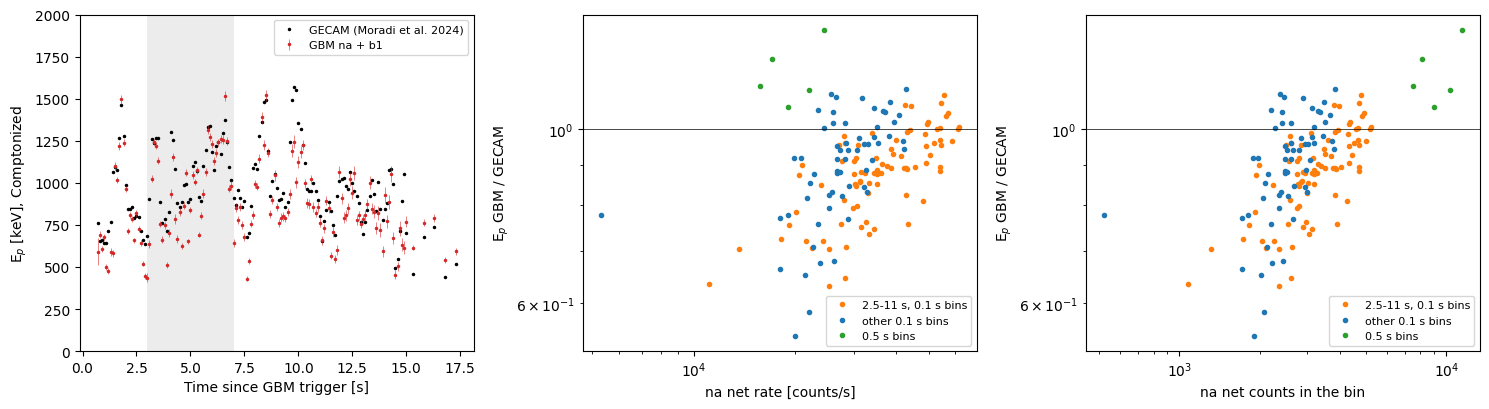

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
flagged_bins = (fits_nab1.t_mid > 2.5) & (fits_nab1.t_mid < 11.0)
long_bins = fits_nab1.duration > 0.2
axes[0].plot(fits_nab1.t_mid, fits_nab1.gecam_Ep, "k.", ms=3, label="GECAM (Moradi et al. 2024)")
axes[0].errorbar(fits_nab1.t_mid, fits_nab1.Ep, yerr=fits_nab1.Ep_err, fmt=".", color="tab:red", ms=3, lw=0.4, label="GBM na + b1")
axes[0].axvspan(*BAD_TIME_INTERVAL, color="grey", alpha=0.15, lw=0)
axes[0].set(xlabel="Time since GBM trigger [s]", ylabel="E$_p$ [keV], Comptonized", ylim=(0, 2000))
axes[0].legend(fontsize=8)
for mask, colour, name in ((flagged_bins, "tab:orange", "2.5-11 s, 0.1 s bins"), (~flagged_bins & ~long_bins, "tab:blue", "other 0.1 s bins"),
                           (long_bins, "tab:green", "0.5 s bins")):
    axes[1].plot(fits_nab1.na_rate[mask], fits_nab1.Ep_ratio[mask], ".", color=colour, label=name)
    axes[2].plot(fits_nab1.na_counts[mask], fits_nab1.Ep_ratio[mask], ".", color=colour, label=name)
axes[1].set(xlabel="na net rate [counts/s]", ylabel="E$_p$ GBM / GECAM")
axes[2].set(xlabel="na net counts in the bin", ylabel="E$_p$ GBM / GECAM")
for ax in axes[1:]:
    ax.set(xscale="log", yscale="log")
    ax.axhline(1, color="k", lw=0.5)
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "15_gbm_vs_gecam.png", dpi=200)
plt.show()

GBM and GECAM follow each other closely through the whole burst, but GBM's E_p is lower: the median is 0.89-0.93 of GECAM's in
0.65-15 s (0.84 +/- 0.06 in the four bins of 2.5-3 s), with alpha harder by 0.15-0.20 (0.34 in 2.5-3 s). In the five 0.5 s bins at
15-17.5 s it goes the other way, 1.14 +/- 0.06, with alpha +0.08. The flux agrees much better: within 4%, and 6% at 15-17.5 s.

- It isn't only the flagged bins. 0.65-2.5 s and 11-15 s have no flag and give 0.93 and 0.91; 3-7 s and 7.5-11 s give 0.92 and 0.89.
- It isn't pile-up in GBM, which would push E_p up, not down (section 5).
- It isn't n6 and n8: with all four detectors the ratios change by at most 0.02.
- It isn't the energy range: fitting GBM over GECAM's energies leaves E_p at 0.83-0.94 in 0.65-15 s. Starting na at 40 keV shrinks
  the alpha offset in 11-15 s to +0.08, but raises it to +0.25 in 0.65-2.5 s.

Where the table's fits include GBM, after 17.5 s, I can check the method itself. The same comparison should then agree, and it
also tells me the table's E_p column is really E_p and not the cut-off energy of the Comptonized model, which would differ by a
factor of (2 + alpha).

In [16]:
after = gecam_table[(gecam_table.t_start >= 17.5) & (gecam_table.t_stop <= 45.0) & (gecam_table.model == "cpl")].reset_index(drop=True)
AFTER_WINDOWS = {f"a{i}": (r.t_start, r.t_stop) for i, r in after.iterrows()}
after_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, AFTER_WINDOWS, BKG_WINDOWS, BKG_ORDER)[0] for d in ("na", "b1")}
rows = []
for key, r in zip(AFTER_WINDOWS, after.itertuples()):
    response = {d: window_response(DATA_DIR, BURST_ID, d, AFTER_WINDOWS[key])[0] for d in ("na", "b1")}
    data = ([after_spectra[d][key][0] for d in ("na", "b1")], [after_spectra[d][key][1] for d in ("na", "b1")], [response[d] for d in ("na", "b1")],
            [channel_mask(response["na"], (8.0, 900.0)), channel_mask(response["b1"], (300.0, 8000.0))])      # their GBM ranges
    model = Comptonized()
    fit = fit_model(*data, model, scaled_starts(model, *data, [[1.0, e, a, 100.0] for e in (200.0, 500.0, 1000.0) for a in (-1.0, -1.5)]), polish=True)
    rows.append(dict(t_start=r.t_start, Ep=fit.parameters[1], alpha=fit.parameters[2], table_Ep=r.Ep_keV, table_alpha=r.alpha))
joint = pd.DataFrame(rows)
joint_ratio = joint.Ep / joint.table_Ep
print(f"{len(joint)} joint bins, 17.55-42.8 s: E_p GBM / table {joint_ratio.median():.3f} +/- {median_error(joint_ratio):.3f}, "
      f"alpha GBM - table {(joint.alpha - joint.table_alpha).median():+.3f}")
print(f"if the column were the cut-off energy, the ratio would be {(joint.Ep / (joint.table_Ep * (2 + joint.table_alpha))).median():.2f}")

21 joint bins, 17.55-42.8 s: E_p GBM / table 1.056 +/- 0.019, alpha GBM - table +0.010
if the column were the cut-off energy, the ratio would be 1.63


With GBM in their fits alpha agrees to 0.01 and E_p to 6%, so the comparison itself works and the column is E_p.

## 7. What the offset follows

If the offset were pile-up in GBM, it would follow the rate. If it came from fitting few counts, it would follow the counts
in the bin. Most bins are 0.1 s long, so the two go together, but the five 0.5 s bins at 15-17.5 s separate them: low rate,
many counts. I fit the trend on the 0.1 s bins and predict the 0.5 s bins with it.

In [17]:
short = fits_nab1[fits_nab1.duration < 0.2]
long = fits_nab1[fits_nab1.duration > 0.2]
rows = []
for name, column in (("na rate", "na_rate"), ("na counts in the bin", "na_counts")):
    slope, intercept = np.polyfit(np.log(short[column]), np.log(short.Ep_ratio), 1)
    scatter = (np.log(short.Ep_ratio) - (slope * np.log(short[column]) + intercept)).std()
    miss = (slope * np.log(long[column]) + intercept - np.log(long.Ep_ratio)).mean()
    rows.append({"against": name, "slope": slope, "scatter": scatter, "prediction_minus_observed_0.5s_bins": miss})
print(pd.DataFrame(rows).set_index("against").round(3).to_string())

for name, mask in (("flagged, 2.5-11 s", (short.t_mid > 2.5) & (short.t_mid < 11.0)),
                   ("not flagged, 0.65-2.5 and 11-15 s", (short.t_mid < 2.5) | (short.t_mid > 11.0))):
    p, cov = np.polyfit(np.log(short.na_rate[mask]), np.log(short.Ep_ratio[mask]), 1, cov=True)
    print(f"slope against rate, {name}: {p[0]:+.3f} +/- {np.sqrt(cov[0, 0]):.3f} ({mask.sum()} bins)")

rows = []
for a, b in ((0, 1500), (1500, 2500), (2500, 3500), (3500, 4500), (4500, 1e9)):
    w = short[(short.na_counts > a) & (short.na_counts <= b)]
    rows.append({"na_counts_in_bin": f"{a:.0f}-{b:.0f}", "bins": len(w), "Ep_ratio": w.Ep_ratio.median(), "Ep_ratio_err": median_error(w.Ep_ratio),
                 "dalpha": w.dalpha.median(), "na_rate": w.na_rate.median()})
rows.append({"na_counts_in_bin": "0.5 s bins", "bins": len(long), "Ep_ratio": long.Ep_ratio.median(), "Ep_ratio_err": median_error(long.Ep_ratio),
             "dalpha": long.dalpha.median(), "na_rate": long.na_rate.median()})
pd.DataFrame(rows).set_index("na_counts_in_bin").round(3)

                      slope  scatter  prediction_minus_observed_0.5s_bins
against                                                                  
na rate               0.220    0.119                               -0.395
na counts in the bin  0.238    0.120                               -0.013
slope against rate, flagged, 2.5-11 s: +0.263 +/- 0.029 (84 bins)
slope against rate, not flagged, 0.65-2.5 and 11-15 s: +0.267 +/- 0.059 (58 bins)


,bins,Ep_ratio,Ep_ratio_err,dalpha,na_rate
na_counts_in_bin,,,,,
0-1500,3,0.704,0.051,0.364,11073.277
1500-2500,39,0.819,0.028,0.211,23366.788
2500-3500,63,0.893,0.015,0.180,31612.734
3500-4500,25,0.953,0.022,0.150,43056.040
4500-1000000000,14,1.001,0.021,0.109,54332.836
0.5 s bins,5,1.137,0.059,0.078,19022.057


The trend with the rate is the same in flagged and unflagged bins (+0.263 +/- 0.029 and +0.267 +/- 0.059 per e-fold), and a line
fitted against the rate misses the 0.5 s bins completely (by -0.40 in ln), while a line fitted against the counts in the bin predicts them
(-0.01). So the offset follows the counts in the bin, not the rate. The ratio goes through 1 as the counts rise: 0.82 +/- 0.03 at 1500-2500 na
counts, 0.89 +/- 0.02 at 2500-3500, 1.00 +/- 0.02 above 4500 and 1.14 +/- 0.06 in the 0.5 s bins, with alpha's offset shrinking from +0.21 to +0.08. So
it isn't a fixed shift between the instruments, and it isn't pile-up. One caution: telling counts from rate rests on those five 0.5 s bins,
which also come later in the burst.

So could the low counts themselves bias a Comptonized fit? For GBM that can be tested by simulation (a check): take the best
fit of 11-13 s, make Poisson spectra with the counts of a shorter bin, fit them the same way and see if E_p comes back.

In [18]:
LOW_COUNT_WINDOW = (11.0, 13.0)
sim_detectors = ["na", "b1"]
sim_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, {"w": LOW_COUNT_WINDOW}, BKG_WINDOWS, BKG_ORDER)[0]["w"] for d in sim_detectors}
sim_response = {d: window_response(DATA_DIR, BURST_ID, d, LOW_COUNT_WINDOW)[0] for d in sim_detectors}
sim_masks = [channel_mask(sim_response[d], FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for d in sim_detectors]
model = Comptonized()
data = ([sim_spectra[d][0] for d in sim_detectors], [sim_spectra[d][1] for d in sim_detectors], [sim_response[d] for d in sim_detectors], sim_masks)
fit_model(*data, model, scaled_starts(model, *data, SHAPES), polish=True)
truth = list(model.default_values)
print(f"input, na + b1, 11-13 s: E_p {truth[1]:.1f} keV, alpha {truth[2]:.3f}")

sim_rng = np.random.default_rng(5)
rows = []
for duration in (0.05, 0.1, 0.2, 0.5, 2.0):
    scale = duration / (LOW_COUNT_WINDOW[1] - LOW_COUNT_WINDOW[0])
    found_ep, found_alpha = [], []
    for _ in range(150):
        phas, baks = [], []
        for d in sim_detectors:
            pha, bkg = sim_spectra[d]
            exposure = pha.exposure * scale
            expected = np.asarray(sim_response[d].drm.fold_spectrum(Comptonized().eval, truth)) * exposure + np.asarray(bkg.counts) * scale
            fake = EnergyBins(sim_rng.poisson(expected), pha.data.lo_edges, pha.data.hi_edges, np.full(pha.num_chans, exposure))
            phas.append(Pha.from_data(fake, gti=pha.gti, trigger_time=pha.trigtime))
            baks.append(BackgroundSpectrum(np.asarray(bkg.rates), np.asarray(bkg.rate_uncertainty), pha.data.lo_edges, pha.data.hi_edges,
                                           np.full(pha.num_chans, exposure)))
        trial = Comptonized()
        trial_data = (phas, baks, [sim_response[d] for d in sim_detectors], sim_masks)
        result = fit_model(*trial_data, trial, scaled_starts(trial, *trial_data, SHAPES), polish=False)
        found_ep.append(result.parameters[1])
        found_alpha.append(result.parameters[2])
    rows.append({"bin_s": duration, "na_counts": float(np.sum(sim_spectra["na"][0].data.counts)) * scale,
                 "Ep_median_over_true": np.median(found_ep) / truth[1], "Ep_scatter": np.std(found_ep) / truth[1],
                 "alpha_median_minus_true": np.median(found_alpha) - truth[2]})
pd.DataFrame(rows).set_index("bin_s").round(3)

input, na + b1, 11-13 s: E_p 819.6 keV, alpha -0.877


,na_counts,Ep_median_over_true,Ep_scatter,alpha_median_minus_true
bin_s,,,,
0.05,1409.75,0.996,0.056,-0.006
0.10,2819.50,0.999,0.042,0.001
0.20,5639.00,0.998,0.027,0.002
0.50,14097.50,1.000,0.017,0.001
2.00,56390.00,1.000,0.008,-0.001


GBM's fits aren't biased at these counts: E_p comes back within 0.4% even at 1400 na counts, and alpha within 0.006. So the trend
doesn't come from fitting few counts in GBM. It could come from the GECAM fits, which is something I can't test without their
data. For the error budget I keep ~10%, the size of the offset over most of the burst, since I can't say which instrument is
closer.

## 8. b1's normalisation, and the detectors compared in one energy band

Two more tests for pile-up in b1 that don't depend on E_p. The first gives b1 a free constant in the fit: if b1 loses counts at
high rates, the constant should fall with the rate. GDT's fitter has no free constant, so I wrote the likelihood out,
and check that it reproduces GDT's C-stat.

In [19]:
def fit_with_constant(row, key, detectors=("na", "b1")):
    geometry = {}
    for d in detectors:
        rsp = bin_response[d]
        low, high = np.asarray(rsp.drm.photon_bins.low_edges()), np.asarray(rsp.drm.photon_bins.high_edges())
        geometry[d] = (np.sqrt(low * high), high - low, np.asarray(rsp.drm.matrix),
                       channel_mask(rsp, FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI))
    compton = Comptonized()

    def statistic(theta, free_constant):
        total = 0.0
        for d in detectors:
            energy, width, matrix, mask = geometry[d]
            pha, bkg = bin_spectra[d][key]
            constant = np.exp(theta[3]) if (free_constant and d == "b1") else 1.0
            source = (compton.eval([np.exp(theta[0]), np.exp(theta[1]), theta[2], 100.0], energy) * width) @ matrix
            mu = np.maximum(constant * source[mask] * pha.exposure + np.asarray(bkg.counts)[mask], 1e-10)
            n = np.asarray(pha.data.counts, float)[mask]
            term = mu - n
            term[n > 0] += n[n > 0] * np.log(n[n > 0] / mu[n > 0])
            total += 2 * term.sum()
        return total

    data = ([bin_spectra[d][key][0] for d in detectors], [bin_spectra[d][key][1] for d in detectors],
            [bin_response[d] for d in detectors], [geometry[d][3] for d in detectors])
    model = Comptonized()
    fit = fit_model(*data, model, scaled_starts(model, *data, SHAPES), polish=True)
    start = np.array([np.log(fit.parameters[0]), np.log(fit.parameters[1]), fit.parameters[2]])
    best = minimize(statistic, np.append(start, 0.0), args=(True,), method="Nelder-Mead",
                    options=dict(maxiter=2000, xatol=1e-3, fatol=1e-3))
    return dict(t_start=row.t_start, t_stop=row.t_stop, c_gdt=cstat(fit), c_mine=statistic(start, False), Ep_no_constant=fit.parameters[1],
                alpha_no_constant=fit.parameters[2], Ep_free=np.exp(best.x[1]), alpha_free=best.x[2], constant=np.exp(best.x[3]), c_free=best.fun)

constants = pd.DataFrame([fit_with_constant(r, key) for key, r in zip(BIN_WINDOWS, bins.itertuples())])
constants = constants.assign(t_mid=fits_nab1.t_mid, na_rate=fits_nab1.na_rate, duration=fits_nab1.duration, b1_live=fits_nab1.b1_live)
print("largest difference between my C-stat and GDT's at the same best fit:", round((constants.c_mine - constants.c_gdt).abs().max(), 3))
print("total Delta C for the free constants:", round((constants.c_mine - constants.c_free).sum(), 1), "for", len(constants), "extra parameters\n")

RATE_GROUPS = ((0, 20e3), (20e3, 30e3), (30e3, 40e3), (40e3, 50e3), (50e3, 1e6))
rows = []
for a, b in RATE_GROUPS:
    w = constants[(constants.na_rate > a) & (constants.na_rate <= b) & (constants.duration < 0.2)]
    rows.append({"na_rate": f"{a / 1e3:.0f}-{b / 1e3:.0f}k", "bins": len(w), "constant": w.constant.median(), "constant_err": median_error(w.constant),
                 "dC_per_bin": (w.c_mine - w.c_free).mean(), "Ep_free_over_none": (w.Ep_free / w.Ep_no_constant).median(),
                 "dalpha": (w.alpha_free - w.alpha_no_constant).median(), "b1_live": w.b1_live.median(),
                 "bins_in_3_7s": ((w.t_mid > 3.0) & (w.t_mid < 7.0)).sum()})
pd.DataFrame(rows).set_index("na_rate").round(3)

largest difference between my C-stat and GDT's at the same best fit: 0.0
total Delta C for the free constants: 362.9 for 149 extra parameters



,bins,constant,constant_err,dC_per_bin,Ep_free_over_none,dalpha,b1_live,bins_in_3_7s
na_rate,,,,,,,,
0-20k,9,1.045,0.033,2.860,0.988,-0.016,0.952,2
20-30k,53,1.025,0.010,1.945,0.993,-0.007,0.930,8
30-40k,45,1.000,0.007,1.299,1.000,0.000,0.899,6
40-50k,22,0.980,0.009,2.085,1.002,0.010,0.852,8
50-1000k,15,0.951,0.010,8.030,1.007,0.021,0.799,15


In [20]:
# Inside one epoch the spectrum changes less, so this is the fairer test. Also regress on E_p, since the constant could follow the spectrum
rows = []
for name, (a, b) in EPOCHS.items():
    w = constants[(constants.t_mid > a) & (constants.t_mid < b)]
    if len(w) < 10:
        continue
    X = np.c_[np.ones(len(w)), np.log(w.na_rate), np.log(w.Ep_no_constant)]
    beta = np.linalg.lstsq(X, w.constant, rcond=None)[0]
    residual = w.constant - X @ beta
    errors = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * residual.var(ddof=3))
    rows.append({"epoch": name, "bins": len(w), "constant": w.constant.median(), "constant_err": median_error(w.constant),
                 "per_e_fold_of_rate": beta[1], "rate_err": errors[1], "per_e_fold_of_Ep": beta[2], "Ep_err": errors[2], "dC_per_bin": (w.c_mine - w.c_free).mean()})
pd.DataFrame(rows).set_index("epoch").round(3)

,bins,constant,constant_err,per_e_fold_of_rate,rate_err,per_e_fold_of_Ep,Ep_err,dC_per_bin
epoch,,,,,,,,
"0.65-2.5 s, no flag",18,1.034,0.020,0.077,0.033,-0.209,0.048,3.206
"3-7 s, TTE losses",39,0.983,0.013,-0.086,0.031,-0.089,0.043,4.528
"7.5-11 s, b1 flagged",34,0.989,0.009,-0.060,0.040,-0.066,0.028,1.559
"11-15 s, no flag",39,1.000,0.008,0.007,0.043,-0.021,0.040,0.853


Across the burst the constant falls with the rate, from 1.045 +/- 0.033 below 20k to 0.951 +/- 0.010 above 50k, where freeing it
helps the fit most (Delta C = 8 per bin). But all 15 of those top bins are inside 3-7 s. Inside each epoch, where the spectrum changes
less, it goes -0.086 +/- 0.031 per e-fold in 3-7 s, -0.060 +/- 0.040 in 7.5-11 s, +0.007 +/- 0.043 in 11-15 s and +0.077 +/- 0.033 in
0.65-2.5 s, where it follows E_p more than the rate. So the only clear drop with the rate is in the interval no window uses.

What matters most here: freeing the constant moves E_p by about 1% at most and alpha by 0.02 at most (medians per rate group). So b1's
normalisation isn't what sets E_peak.

The second test compares detectors in one energy band, where no fit is involved. In each bin I fold GECAM's published spectrum
through each GBM response to get the counts predicted in 300-900 keV, a band that b1, na, n6 and n8 all cover, and
take observed over predicted. Then the ratio of one detector to another cancels whatever is wrong with GECAM's spectrum in that
bin. If b1 loses counts at high rate, b1/n6 and b1/n8 should fall with the rate while n6/n8 stays put.

In [21]:
compton = Comptonized()
rows = []
for key, r in zip(BIN_WINDOWS, bins.itertuples()):
    amplitude = r.flux_erg_cm2_s / energy_flux(compton, [1.0, r.Ep_keV, r.alpha, 100.0], (6.0, 8000.0))
    row = dict(t_start=r.t_start, t_stop=r.t_stop)
    for det in SPECTRAL_DETECTORS:
        pha, bkg = bin_spectra[det][key]
        lo, hi = channel_edges(bin_response[det])
        predicted = np.asarray(bin_response[det].drm.fold_spectrum(compton.eval, [amplitude, r.Ep_keV, r.alpha, 100.0])) * pha.exposure
        counts, background = np.asarray(pha.data.counts, float), np.asarray(bkg.counts)
        for a, b in BANDS[det]:
            mask = (lo >= a) & (hi <= b)
            row.update({f"{det}_{a}_{b}_obs": (counts - background)[mask].sum(), f"{det}_{a}_{b}_tot": counts[mask].sum(),
                        f"{det}_{a}_{b}_pred": predicted[mask].sum()})
    rows.append(row)
folded = pd.DataFrame(rows).assign(t_mid=fits_nab1.t_mid, na_rate=fits_nab1.na_rate, duration=fits_nab1.duration, b1_live=fits_nab1.b1_live)

def same_band_ratio(w, first, second, band="300_900"):
    a = w[f"{first}_{band}_obs"].sum() / w[f"{first}_{band}_pred"].sum()
    b = w[f"{second}_{band}_obs"].sum() / w[f"{second}_{band}_pred"].sum()
    ratio = a / b
    return ratio, ratio * np.hypot(np.sqrt(w[f"{first}_{band}_tot"].sum()) / w[f"{first}_{band}_obs"].sum(),
                                   np.sqrt(w[f"{second}_{band}_tot"].sum()) / w[f"{second}_{band}_obs"].sum())

PAIRS = (("b1", "n6"), ("b1", "n8"), ("na", "n6"), ("n6", "n8"))
tenth = folded[folded.duration < 0.2]
rows = []
for a, b in ((0, 25e3), (25e3, 35e3), (35e3, 50e3), (50e3, 1e6)):
    w = tenth[(tenth.na_rate > a) & (tenth.na_rate <= b)]
    rows.append({"na_rate": f"{a / 1e3:.0f}-{b / 1e3:.0f}k", "bins": len(w),
                 **{f"{x}/{y}": "{:.3f} +/- {:.3f}".format(*same_band_ratio(w, x, y)) for x, y in PAIRS}})
print("All 0.1 s bins, 300-900 keV")
print(pd.DataFrame(rows).set_index("na_rate").to_string(), "\n")

rows = []
changes = []
for name in ("0.65-2.5 s, no flag", "3-7 s, TTE losses", "7.5-11 s, b1 flagged", "11-15 s, no flag"):
    a, b = EPOCHS[name]
    w = tenth[(tenth.t_mid > a) & (tenth.t_mid < b)]
    median = w.na_rate.median()
    below, above = w[w.na_rate <= median], w[w.na_rate > median]
    row = {"epoch": name, "na_rate_below": below.na_rate.median(), "na_rate_above": above.na_rate.median()}
    for x, y in PAIRS:
        r0, e0 = same_band_ratio(below, x, y)
        r1, e1 = same_band_ratio(above, x, y)
        row[f"change {x}/{y}"] = f"{r1 - r0:+.3f} +/- {np.hypot(e0, e1):.3f}"
        if (x, y) == ("b1", "n6"):
            changes.append((r1 - r0, np.hypot(e0, e1)))
    rows.append(row)
print("Inside each epoch: bins above the epoch's median rate minus bins below it, 300-900 keV")
print(pd.DataFrame(rows).set_index("epoch").round(0).to_string())
changes = np.array(changes)
weights = 1 / changes[:, 1]**2
print(f"\nb1/n6, the four epochs combined: {np.sum(changes[:, 0] * weights) / weights.sum():+.3f} +/- {1 / np.sqrt(weights.sum()):.3f}")

All 0.1 s bins, 300-900 keV
          bins            b1/n6            b1/n8            na/n6            n6/n8
na_rate                                                                           
0-25k       28  1.108 +/- 0.023  1.239 +/- 0.034  1.041 +/- 0.026  1.119 +/- 0.037
25-35k      63  1.096 +/- 0.011  1.120 +/- 0.014  1.069 +/- 0.013  1.023 +/- 0.016
35-50k      38  1.033 +/- 0.010  1.097 +/- 0.013  1.046 +/- 0.013  1.063 +/- 0.016
50-1000k    15  0.996 +/- 0.012  1.051 +/- 0.016  1.078 +/- 0.016  1.055 +/- 0.019 

Inside each epoch: bins above the epoch's median rate minus bins below it, 300-900 keV
                      na_rate_below  na_rate_above      change b1/n6      change b1/n8      change na/n6      change n6/n8
epoch                                                                                                                     
0.65-2.5 s, no flag         20013.0        35035.0  -0.073 +/- 0.041  -0.132 +/- 0.059  +0.001 +/- 0.048  -0.050 +/- 0.065
3-7 s, TTE losse

b1 falls against n6 and n8 as the rate rises, while na/n6 doesn't. The whole-burst rows mix in spectral evolution, so the
inside-epoch rows are the fair ones: b1/n6 falls in all four epochs, -0.046 +/- 0.014 combined (3.3 sigma), about half of the weight
coming from 3-7 s. The simulation predicts about -0.01 for this ratio, with b1 flat in this band and n6 up by ~1%. So b1 does lose counts
at high rates, by a few percent, and somewhat more than my simulation says. Small pulses below b1's threshold, which aren't simulated, could be
part of the reason.

This is the test script 07 should have been. It shows a loss in b1 that depends on the rate, so "no sign of pile-up" was wrong.

## 9. The low-energy band

Folding GECAM's spectra through na also gives a look at the open point from notebook 12: below ~40 keV the data don't follow
the Band shape fitted above it, and na is the only GBM detector that sees those energies. GECAM-C does too, down to 6 keV.

In [22]:
rows = []
GROUPS = (("below 25k", tenth[tenth.na_rate <= 25e3]), ("25-35k", tenth[(tenth.na_rate > 25e3) & (tenth.na_rate <= 35e3)]),
          ("35-50k", tenth[(tenth.na_rate > 35e3) & (tenth.na_rate <= 50e3)]), ("above 50k", tenth[tenth.na_rate > 50e3]),
          ("0.5 s bins", folded[folded.duration > 0.2]))
for det in BANDS:
    for a, b in BANDS[det]:
        row = {"band": f"{det} {a}-{b} keV"}
        for name, w in GROUPS:
            observed, total, predicted = w[f"{det}_{a}_{b}_obs"].sum(), w[f"{det}_{a}_{b}_tot"].sum(), w[f"{det}_{a}_{b}_pred"].sum()
            row[name] = f"{observed / predicted:.3f} +/- {np.sqrt(total) / predicted:.3f}"
        rows.append(row)
print("Observed net counts over the counts predicted from GECAM's spectrum, by na rate. Bins:", [len(w) for _, w in GROUPS])
pd.DataFrame(rows).set_index("band")

Observed net counts over the counts predicted from GECAM's spectrum, by na rate. Bins: [28, 63, 38, 15, 5]


,below 25k,25-35k,35-50k,above 50k,0.5 s bins
band,,,,,
n6 50-100 keV,0.962 +/- 0.014,1.033 +/- 0.008,1.039 +/- 0.009,1.013 +/- 0.013,1.039 +/- 0.017
n6 100-300 keV,0.965 +/- 0.009,1.036 +/- 0.005,1.072 +/- 0.006,1.045 +/- 0.007,0.959 +/- 0.011
n6 300-900 keV,0.862 +/- 0.017,0.980 +/- 0.009,1.058 +/- 0.010,1.067 +/- 0.012,1.023 +/- 0.026
n8 50-100 keV,0.933 +/- 0.018,0.997 +/- 0.010,1.008 +/- 0.011,0.998 +/- 0.015,0.961 +/- 0.021
n8 100-300 keV,0.936 +/- 0.011,1.017 +/- 0.007,1.058 +/- 0.007,1.042 +/- 0.009,0.944 +/- 0.015
n8 300-900 keV,0.770 +/- 0.020,0.958 +/- 0.012,0.995 +/- 0.012,1.011 +/- 0.015,0.968 +/- 0.034
na 15-40 keV,0.746 +/- 0.008,0.791 +/- 0.005,0.837 +/- 0.006,0.841 +/- 0.009,0.884 +/- 0.008
na 40-100 keV,0.877 +/- 0.007,0.932 +/- 0.004,0.922 +/- 0.005,0.888 +/- 0.007,0.963 +/- 0.008
na 100-300 keV,0.950 +/- 0.007,1.024 +/- 0.004,1.031 +/- 0.004,0.999 +/- 0.006,0.959 +/- 0.008


At 100-300 keV all three NaI agree with GECAM to within ~7%, so the two instruments broadly agree on the normalisation. But
na is well below the prediction at low energies, in every group: 12-25% low in 15-40 keV and 4-12% low in 40-100 keV. That is the same
direction as GBM's harder alpha. It shrinks as the rate rises, so it isn't pile-up, which the simulation gives as at most 5.5% and
growing with the rate. Either the spectrum really does flatten at low energies, more than a Comptonized fit to GECAM's data can show, or
na's response or GECAM-C's is off there (the authors flag GECAM-C below 15 keV). This doesn't settle the low-energy break from notebook 12,
but it does show that published fits can't settle it: it needs GECAM's actual data.

In b1 above 900 keV the ratio climbs with the counts (0.66 to 1.36 in 900-3000 keV), like the E_p offset. The 3000-8000 keV points go
from 0.26 to 1.87 +/- 0.42. These compare data with a Comptonized shape that has no high-energy tail, so I wouldn't read more into them.

## 10. The precursor

The window that matters most for the project. Neither GBM's flags nor the simulation touch it: b1 records at most ~20 kcps here,
and section 5 gives a bias of at most 0.3%. But Moradi et al.'s table does have bins here, and they are lower. These are joint
GECAM and GBM fits, so not independent of my data, but they are the only other published numbers at this resolution. I fit the same
bins with GBM alone, with na + b1 and with all four. If their T0 were different from GBM's, sharp features would land in different bins,
so first the time offset: the net NaI rate in the table's bins, shifted, against their flux.

In [23]:
def nai_rate(t0, t1):
    return sum(np.searchsorted(events[d], t1) - np.searchsorted(events[d], t0) for d in ("n6", "n8", "na")) / (t1 - t0)

def nai_background():
    return sum(np.sum((events[d] > -7.0) & (events[d] < -2.0)) / 5.0 for d in ("n6", "n8", "na"))

shifts = np.arange(-0.040, 0.0401, 0.002)
boot_rng = np.random.default_rng(3)
rows = []
for name, (a, b) in {"-0.05 to 0.35 s": (-0.05, 0.35), "-0.05 to 3 s": (-0.05, 3.0), "3-7 s": (3.0, 7.0), "7-15 s": (7.0, 15.0)}.items():
    w = gecam_table[(gecam_table.t_start >= a - 1e-6) & (gecam_table.t_stop <= b + 1e-6)]
    level = nai_background()
    grid = np.array([[nai_rate(r.t_start + s, r.t_stop + s) - level for r in w.itertuples()] for s in shifts])
    flux = np.log(w.flux_erg_cm2_s.values)

    def best_shift(sample):
        corr = np.array([np.corrcoef(np.log(np.maximum(line[sample], 1.0)), flux[sample])[0, 1] for line in grid])
        i = int(np.nanargmax(corr))
        if 0 < i < len(corr) - 1:
            p = np.polyfit(shifts[i - 1:i + 2], corr[i - 1:i + 2], 2)
            return -p[1] / (2 * p[0])
        return shifts[i]
    boots = [best_shift(boot_rng.integers(0, len(w), len(w))) for _ in range(200)] if len(w) > 10 else [np.nan]
    rows.append({"interval": name, "bins": len(w), "best_shift_ms": 1e3 * best_shift(np.arange(len(w))), "bootstrap_ms": 1e3 * np.std(boots)})
print(pd.DataFrame(rows).set_index("interval").round(1).to_string())

first = gecam_table[gecam_table.t_stop <= 0.36]
print("\nprecursor bins, flux relative to the brightest bin:")
print("GECAM + GBM flux:", (first.flux_erg_cm2_s / first.flux_erg_cm2_s.max()).round(3).tolist())
for shift in (-0.02, -0.01, 0.0, 0.01, 0.02):
    net = np.array([nai_rate(r.t_start + shift, r.t_stop + shift) - nai_background() for r in first.itertuples()])
    print(f"GBM NaI net rate, shifted {1e3 * shift:+4.0f} ms:", (net / net.max()).round(3).tolist())

                 bins  best_shift_ms  bootstrap_ms
interval                                          
-0.05 to 0.35 s     4            2.0           NaN
-0.05 to 3 s       30           32.4          22.6
3-7 s              39           -6.2          18.0
7-15 s             79           -0.3          12.8

precursor bins, flux relative to the brightest bin:
GECAM + GBM flux: [0.567, 1.0, 0.625, 0.163]
GBM NaI net rate, shifted  -20 ms: [0.287, 1.0, 0.789, 0.243]
GBM NaI net rate, shifted  -10 ms: [0.419, 1.0, 0.701, 0.24]
GBM NaI net rate, shifted   +0 ms: [0.531, 1.0, 0.596, 0.227]
GBM NaI net rate, shifted  +10 ms: [0.662, 1.0, 0.514, 0.211]
GBM NaI net rate, shifted  +20 ms: [0.761, 1.0, 0.442, 0.192]


In [24]:
PRE_BINS = {f"{r.t_start:g}-{r.t_stop:g}": (r.t_start, r.t_stop) for r in first.itertuples()}
PRE_BINS["-0.05-0.25"] = (-0.05, 0.25)
PRE_BINS["-0.064-0.32"] = PRECURSOR
pre_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, PRE_BINS, BKG_WINDOWS, BKG_ORDER)[0] for d in SPECTRAL_DETECTORS}
pre_response = {d: window_response(DATA_DIR, BURST_ID, d, PRECURSOR)[0] for d in SPECTRAL_DETECTORS}
BAND_SHAPES = [[1.0, e, a, b, 100.0] for e in (100.0, 170.0, 300.0) for a in (-0.3, -0.8) for b in (-2.6, -4.0)]

def fit_precursor(label, detectors, fixed_beta=None, model=None):
    window_masks = [channel_mask(pre_response[d], FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for d in detectors]
    data = ([pre_spectra[d][label][0] for d in detectors], [pre_spectra[d][label][1] for d in detectors],
            [pre_response[d] for d in detectors], window_masks)
    function = Band()
    shapes = BAND_SHAPES
    if fixed_beta is not None:
        function.free = [True, True, True, False, False]
        shapes = [[1.0, e, a, fixed_beta, 100.0] for e in (100.0, 170.0, 300.0) for a in (-0.3, -0.8)]
    fit = fit_model(*data, function, scaled_starts(function, *data, shapes), polish=True)
    with np.errstate(invalid="ignore"):
        errors = np.sqrt(np.diag(covariance(fit)))
    return fit.parameters, errors, cstat(fit), fit.dof

rows = []
for label, (a, b) in PRE_BINS.items():
    table_row = first[(first.t_start == a) & (first.t_stop == b)]
    row = {"bin": label}
    if len(table_row):
        t = table_row.iloc[0]
        row.update({"table_model": t.model, "table_Ep": t.Ep_keV, "table_Ep_err": 0.5 * (t.Ep_err_hi + t.Ep_err_lo), "table_alpha": t.alpha, "table_beta": t.beta, "table_C_dof": f"{t.cstat:.0f}/{t.dof:.0f}"})
    for name, detectors in (("na_b1", ["na", "b1"]), ("all4", SPECTRAL_DETECTORS)):
        p, e, c, dof = fit_precursor(label, detectors)
        row.update({f"Ep_{name}": p[1], f"Ep_err_{name}": e[1], f"alpha_{name}": p[2], f"beta_{name}": p[3], f"C_dof_{name}": f"{c:.0f}/{dof}"})
    if len(table_row) and np.isfinite(table_row.iloc[0].beta):
        p, e, c, dof = fit_precursor(label, ["na", "b1"], fixed_beta=table_row.iloc[0].beta)
        row.update({"Ep_na_b1_at_table_beta": p[1], "Ep_err_at_table_beta": e[1], "alpha_at_table_beta": p[2], "dC_at_table_beta": c - float(row["C_dof_na_b1"].split("/")[0])})
    rows.append(row)
pre_table = pd.DataFrame(rows).set_index("bin")
print(pre_table[["table_model", "table_Ep", "table_Ep_err", "table_alpha", "table_beta", "table_C_dof"]].round(2).to_string(), "\n")
print(pre_table[["Ep_na_b1", "Ep_err_na_b1", "alpha_na_b1", "beta_na_b1", "C_dof_na_b1", "Ep_all4", "Ep_err_all4", "alpha_all4", "beta_all4", "C_dof_all4"]].round(2).to_string(), "\n")
print(pre_table[["Ep_na_b1_at_table_beta", "Ep_err_at_table_beta", "alpha_at_table_beta", "dC_at_table_beta"]].round(2).to_string())
weights = first.flux_erg_cm2_s[first.t_stop <= 0.26]
print("\nflux-weighted E_p of the table's first three bins:", round(np.sum(first.Ep_keV[first.t_stop <= 0.26] * weights) / weights.sum(), 1), "keV")

            table_model  table_Ep  table_Ep_err  table_alpha  table_beta table_C_dof
bin                                                                                 
-0.05-0.05         band    148.68          6.15        -0.34       -2.53     600/600
0.05-0.15          band    150.90          4.50        -0.30       -2.77     745/600
0.15-0.25          band    128.47          4.50        -0.44       -2.61     619/600
0.25-0.35           cpl     73.42          3.54        -1.22         NaN     584/601
-0.05-0.25          NaN       NaN           NaN          NaN         NaN         NaN
-0.064-0.32         NaN       NaN           NaN          NaN         NaN         NaN 

             Ep_na_b1  Ep_err_na_b1  alpha_na_b1  beta_na_b1 C_dof_na_b1  Ep_all4  Ep_err_all4  alpha_all4  beta_all4 C_dof_all4
bin                                                                                                                             
-0.05-0.05     197.77         14.26        -0.36       -2.54

Time zero first. The precursor's fast rise fixes it: the NaI rate in the table's bins matches their pattern of flux (0.57, 1, 0.63)
at no shift (0.53, 1, 0.60), and not at +/-10 ms (0.42, 1, 0.70 and 0.66, 1, 0.51). So any offset is a few ms, and can't explain a
difference. The main emission only limits it to about +/-20 ms.

In the last bin GBM agrees with the joint fit (72 +/- 5 against 73 +/- 4 keV, same alpha), and in 0.15-0.25 s nearly (139 +/- 8 against 128 +/- 5).
In the first two bins GBM's E_p is higher: 198 +/- 14 against 149 +/- 6, and 206 +/- 6 against 151 +/- 5. In the first, alpha and beta agree to 0.02,
so it is E_p itself. In the second it is the tail: GBM doesn't want one (beta runs to its limit), and if I force their beta = -2.77,
E_p falls to 167 +/- 6 keV but the C-stat is 28 worse. Their own C-stat for that bin, 745 for 600 dof, is the worst of the four. Weighted
by flux, their first three bins give 144 keV, against 178 +/- 6 keV from GBM alone over the same 0.3 s.

So the precursor has an instrument uncertainty of its own, ~20%, larger than in the main emission and not from pile-up. I can't say
which is right, since these fits contain GBM and GECAM together and only the published numbers are available. It doesn't change what matters
for the project: 140-180 keV, five to seven times softer than the emission that follows.

## 11. Other detector choices

**b0 as a second BGO.** At first sight b0 looks like a control for b1: same kind of detector, lower rate. But the GBM team say all
detectors except na and b1 are too far off axis or blocked, and these fits show why that matters.

In [25]:
main_labels = [label for label in windows.index if label.startswith("m")]
WINDOW_DICT = {label: (windows.loc[label, "t_start"], windows.loc[label, "t_stop"]) for label in main_labels}
GRID = [[1.0, e, a, b, 100.0] for e in (200.0, 450.0, 900.0) for a in (-0.6, -1.2) for b in (-2.6, -4.0, -6.0)]
b0_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, WINDOW_DICT, BKG_WINDOWS, BKG_ORDER)[0] for d in ("na", "b1", "b0")}
rows = []
for label, window in WINDOW_DICT.items():
    response = {d: window_response(DATA_DIR, BURST_ID, d, window)[0] for d in ("na", "b1", "b0")}
    row = {"label": label, "window": f"{window[0]:g}-{window[1]:g} s"}
    for bgo in ("b1", "b0"):
        pair = ["na", bgo]
        data = ([b0_spectra[d][label][0] for d in pair], [b0_spectra[d][label][1] for d in pair], [response[d] for d in pair],
                [channel_mask(response[d], FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for d in pair])
        model = Band()
        fit = fit_model(*data, model, scaled_starts(model, *data, GRID), polish=True)
        row.update({f"Epeak_{bgo}": fit.parameters[1], f"C_{bgo}": cstat(fit)})
    row["b1_over_b0"] = row["Epeak_b1"] / row["Epeak_b0"]
    rows.append(row)
pd.DataFrame(rows).set_index("label").round(2)

,window,Epeak_b1,C_b1,Epeak_b0,C_b0,b1_over_b0
label,,,,,,
m01,0.32-3 s,918.20,612.57,821.31,2059.96,1.12
m02,7-9 s,979.55,509.36,813.69,2768.34,1.20
m03,9-11 s,955.75,509.91,772.92,2514.55,1.24
m04,11-13 s,814.75,710.73,558.62,2181.48,1.46
m05,13-15 s,794.45,737.45,512.15,1955.91,1.55
m06,15-18.5 s,638.58,736.55,362.25,1460.18,1.76
m07,18.5-22 s,622.60,868.58,266.55,1491.04,2.34
m08,22-25.5 s,481.39,646.16,231.57,988.57,2.08
m09,25.5-29 s,406.14,694.43,190.10,809.47,2.14


b0 isn't a control. Its fits are far worse in the bright windows (C-stat 2060 against 613 in 0.32-3 s), and its E_peak differs
most in the faint windows (b1/b0 is 1.12 in 0.32-3 s and 2.34 in 18.5-22 s), so whatever is wrong follows the response and not the
rate. That supports the GBM team's advice.

**The NaI and b1 fitted apart.** If pile-up in b1 were pushing E_peak up in the flagged windows, b1 alone should disagree with the NaI
alone there, and agree later on. I fit Comptonized spectra to pieces of the burst cut at the GBM team's edges, with each subset
of detectors on its own.

In [26]:
CUTS = {"0.32-2.5": (0.32, 2.5), "2.5-3": (2.5, 3.0), "7-7.5": (7.0, 7.5), "7.5-9": (7.5, 9.0), "9-11": (9.0, 11.0), "11-13": (11.0, 13.0),
        "13-15": (13.0, 15.0), "15-18.5": (15.0, 18.5), "18.5-22": (18.5, 22.0)}
SUBSETS = {"na_b1": ["na", "b1"], "all4": SPECTRAL_DETECTORS, "NaI": ["n6", "n8", "na"], "na": ["na"], "b1": ["b1"]}
SHAPES_CUT = [[1.0, e, a, 100.0] for e in (500.0, 1100.0) for a in (-0.6, -1.1)]
cut_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, CUTS, BKG_WINDOWS, BKG_ORDER)[0] for d in SPECTRAL_DETECTORS}
rows = []
for name, window in CUTS.items():
    response = {d: window_response(DATA_DIR, BURST_ID, d, window)[0] for d in SPECTRAL_DETECTORS}
    row = {"window": name, "b1_max_kcps": rates.loc[inside(rates.index, window), "b1"].max()}
    for subset, detectors in SUBSETS.items():
        data = ([cut_spectra[d][name][0] for d in detectors], [cut_spectra[d][name][1] for d in detectors], [response[d] for d in detectors],
                [channel_mask(response[d], FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for d in detectors])
        model = Comptonized()
        fit = fit_model(*data, model, scaled_starts(model, *data, SHAPES_CUT), polish=True)
        with np.errstate(invalid="ignore"):
            errors = np.sqrt(np.diag(covariance(fit)))
        row.update({f"Ep_{subset}": fit.parameters[1], f"err_{subset}": errors[1], f"alpha_{subset}": fit.parameters[2]})
    row["b1_over_NaI"] = row["Ep_b1"] / row["Ep_NaI"]
    row["b1_over_NaI_err"] = row["b1_over_NaI"] * np.hypot(row["err_b1"] / row["Ep_b1"], row["err_NaI"] / row["Ep_NaI"])
    rows.append(row)
cuts = pd.DataFrame(rows).set_index("window")
cuts[["b1_max_kcps", "Ep_na_b1", "err_na_b1", "Ep_NaI", "err_NaI", "Ep_na", "err_na", "Ep_b1", "err_b1", "b1_over_NaI", "b1_over_NaI_err",
      "alpha_NaI", "alpha_b1"]].round(3)

,b1_max_kcps,Ep_na_b1,err_na_b1,Ep_NaI,err_NaI,Ep_na,err_na,Ep_b1,err_b1,b1_over_NaI,b1_over_NaI_err,alpha_NaI,alpha_b1
window,,,,,,,,,,,,,
0.32-2.5,86.937,967.524,6.007,1133.238,26.696,1393.602,61.014,941.524,5.972,0.831,0.020,-0.540,-0.321
2.5-3,46.062,662.796,9.217,673.322,22.951,758.146,42.894,641.373,9.264,0.953,0.035,-0.452,-0.269
7-7.5,56.625,793.553,11.254,714.100,23.969,750.028,38.598,801.412,12.937,1.122,0.042,-0.658,-0.814
7.5-9,75.312,1047.871,7.574,915.040,19.015,1050.740,37.389,1064.502,8.728,1.163,0.026,-0.662,-0.837
9-11,64.875,963.672,6.605,791.975,13.886,823.512,22.203,978.562,7.351,1.236,0.024,-0.676,-0.781
11-13,45.687,819.564,7.074,636.142,11.639,663.136,18.401,835.247,8.327,1.313,0.027,-0.812,-1.004
13-15,42.062,799.167,8.636,591.819,12.694,600.166,18.884,820.322,10.467,1.386,0.035,-0.971,-1.161
15-18.5,30.375,642.883,8.228,508.840,11.766,496.506,16.042,642.379,10.422,1.262,0.036,-1.105,-1.261
18.5-22,20.688,627.193,8.725,492.581,12.143,475.438,16.164,621.066,11.510,1.261,0.039,-1.162,-1.334


The NaI and b1 do disagree, by a lot, but not the way pile-up would make them. b1/NaI goes from 0.83 +/- 0.02 in 0.32-2.5 s, where b1's rate
is highest, to 1.39 +/- 0.04 in 13-15 s, at half that rate, and it is still 1.26 +/- 0.04 in 18.5-22 s, at 21 kcps. That is a problem
with the shape: a Comptonized fit to the NaI only sees the curvature below 900 keV and one to b1 only what's above ~200 keV, and they don't
agree on one cut-off. It is the same lack of fit that gives C-stat/dof ~2 in notebook 12. The joint E_p stays within ~3% of b1's in
every piece, so b1 sets E_peak in these windows, which is why its rate matters more than the NaI's.

Cutting the windows at the GBM team's edges doesn't help either. E_p is 968 keV in 0.32-2.5 s and 663 keV in 2.5-3 s, 794 keV in 7-7.5 s and
1048 keV in 7.5-9 s, but it really does change that fast, so those jumps can't be read as pile-up.

## 12. What goes in the error budget

One table per window, kept separate from `shared/epeak_230307A.csv` so that file stays the reproduction of Dichiara's analysis. It holds
the share of the window flagged by the GBM team, the highest rate in b1, the simulated pile-up bias, and GECAM's E_p for the same
stretch (energy-weighted mean of its bins) with the ratio. The ratio compares a Band fit to a whole window with an average of
0.1 s Comptonized fits, so it is a rough check rather than a measurement.

In [27]:
rows = []
for label, row in windows.iterrows():
    mid = 0.5 * (gecam_table.t_start + gecam_table.t_stop)
    w = gecam_table[(mid > row.t_start) & (mid < row.t_stop) & gecam_table.Ep_keV.notna()]
    fluence = w.flux_erg_cm2_s * (w.t_stop - w.t_start)
    mean_ep = np.sum(w.Ep_keV * fluence) / fluence.sum() if len(w) else np.nan
    only_gecam = ((w.t_start >= 0.65) & (w.t_stop <= 17.6)).mean() if len(w) else np.nan
    rows.append({"label": label, "t_start": row.t_start, "t_stop": row.t_stop, "Epeak_keV": epeak.loc[label, "Epeak_keV"],
                 "share_na_pileup": flagged.loc[label, "share_na_pileup"], "share_b1_pileup": flagged.loc[label, "share_b1_pileup"],
                 "b1_max_kcps": rates.loc[inside(rates.index, (row.t_start, row.t_stop)), "b1"].max(),
                 "pileup_Epeak_ratio_sim": bias.loc[label, "Epeak_ratio_all4"], "pileup_dalpha_sim": bias.loc[label, "dalpha_all4"],
                 "gecam_Ep_keV": mean_ep, "gecam_share_of_bins_without_gbm": only_gecam, "Epeak_over_gecam": epeak.loc[label, "Epeak_keV"] / mean_ep,
                 "Epeak_instrument_frac": 0.20 if label == "pre" else 0.10})       # my rounding of sections 10 and 6
instrument = pd.DataFrame(rows).set_index("label")
instrument.to_csv(SHARED / "epeak_230307A_instrument_check.csv", float_format="%.5g")
instrument.round(3)

,t_start,t_stop,Epeak_keV,share_na_pileup,share_b1_pileup,b1_max_kcps,pileup_Epeak_ratio_sim,pileup_dalpha_sim,gecam_Ep_keV,gecam_share_of_bins_without_gbm,Epeak_over_gecam,Epeak_instrument_frac
label,,,,,,,,,,,,
pre,-0.064,0.32,170.300,0.000,0.000,20.937,1.000,0.008,139.059,0.000,1.225,0.2
m01,0.320,3.00,914.041,0.187,0.187,86.937,1.033,-0.009,1012.959,1.000,0.902,0.1
m02,7.000,9.00,967.340,0.250,1.000,75.312,1.038,-0.002,1137.419,1.000,0.850,0.1
m03,9.000,11.00,945.582,0.000,1.000,64.875,1.028,0.000,1135.782,1.000,0.833,0.1
m04,11.000,13.00,802.154,0.000,0.000,45.687,1.021,0.001,904.383,1.000,0.887,0.1
m05,13.000,15.00,780.922,0.000,0.000,42.062,1.014,0.003,893.112,1.000,0.874,0.1
m06,15.000,18.50,630.922,0.000,0.000,30.375,1.010,0.002,559.319,0.714,1.128,0.1
m07,18.500,22.00,615.373,0.000,0.000,20.688,1.007,0.001,627.365,0.000,0.981,0.1
m08,22.000,25.50,468.676,0.000,0.000,14.000,1.004,-0.000,434.427,0.000,1.079,0.1


What I take from all this:

1. **3-7 s is the telemetry limit, not pile-up.** The summed rate reaches 375 kHz only there, and the stream goes unusually regular
   at that point.
2. **Pile-up is there, and small.** b1 loses a few percent against the NaI at high rates, and the simulation has E_peak too high by up
   to ~4% in the bright windows. The precursor isn't affected.
3. **GBM and GECAM differ by ~10% in the bright phase and ~20% in the precursor.** Pile-up doesn't explain that: the offset follows the counts
   in a bin, and pile-up would push it the other way. I can't say which instrument is closer, so it goes in as an uncertainty,
   `Epeak_instrument_frac`.
4. **So the errors in the E_peak table are the precision, not the accuracy.** +/-5 keV on 900 keV is what the fit knows. The real
   uncertainty on the value is ~10%, and for the precursor ~20%.
5. **For the project that's fine, within limits.** The precursor is five to seven times softer than the main emission whichever numbers I use
   (139-170 keV against 914-1013 keV). A diagnostic based on that contrast is safe. One that needs E_peak to better than ~20%, or that
   compares a GBM precursor with values from another instrument, is not.

And two things to ask: why the GBM team's b1 interval starts at 2.5 s when b1's rate at ~1.8 s is just as high, and whether the gaps just after
CSPEC edges are known.